# Nível de estresse de estudantes: o que influencia e como prever

**Objetivo:** entender quais fatores estão ligados ao nível de estresse de estudantes e treinar um modelo que prevê esse nível a partir de um questionário curto.

**Dados:** `StressLevelDataset.csv` (Kaggle), com 1.100 estudantes e 20 fatores psicológicos, físicos, sociais, ambientais e acadêmicos. A coluna `stress_level` é o nível de estresse: **0 = baixo, 1 = moderado, 2 = alto**.

> Este é um projeto de estudo. O modelo não substitui uma avaliação feita por um profissional de saúde.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

In [2]:
df_estresse = pd.read_csv('csv/StressLevelDataset.csv')
df_estresse.info()

<class 'pandas.DataFrame'>
RangeIndex: 1100 entries, 0 to 1099
Data columns (total 21 columns):
 #   Column                        Non-Null Count  Dtype
---  ------                        --------------  -----
 0   anxiety_level                 1100 non-null   int64
 1   self_esteem                   1100 non-null   int64
 2   mental_health_history         1100 non-null   int64
 3   depression                    1100 non-null   int64
 4   headache                      1100 non-null   int64
 5   blood_pressure                1100 non-null   int64
 6   sleep_quality                 1100 non-null   int64
 7   breathing_problem             1100 non-null   int64
 8   noise_level                   1100 non-null   int64
 9   living_conditions             1100 non-null   int64
 10  safety                        1100 non-null   int64
 11  basic_needs                   1100 non-null   int64
 12  academic_performance          1100 non-null   int64
 13  study_load                    1100 non-null 

In [3]:
df_estresse['stress_level'].value_counts().sort_index()

stress_level
0    373
1    358
2    369
Name: count, dtype: int64

As três classes estão equilibradas, com cerca de um terço dos estudantes em cada nível: 373 com estresse baixo, 358 moderado e 369 alto. Isso ajuda o modelo, porque ele não fica "viciado" em prever sempre a classe mais comum.

## 1. Correlação de cada fator com o nível de estresse

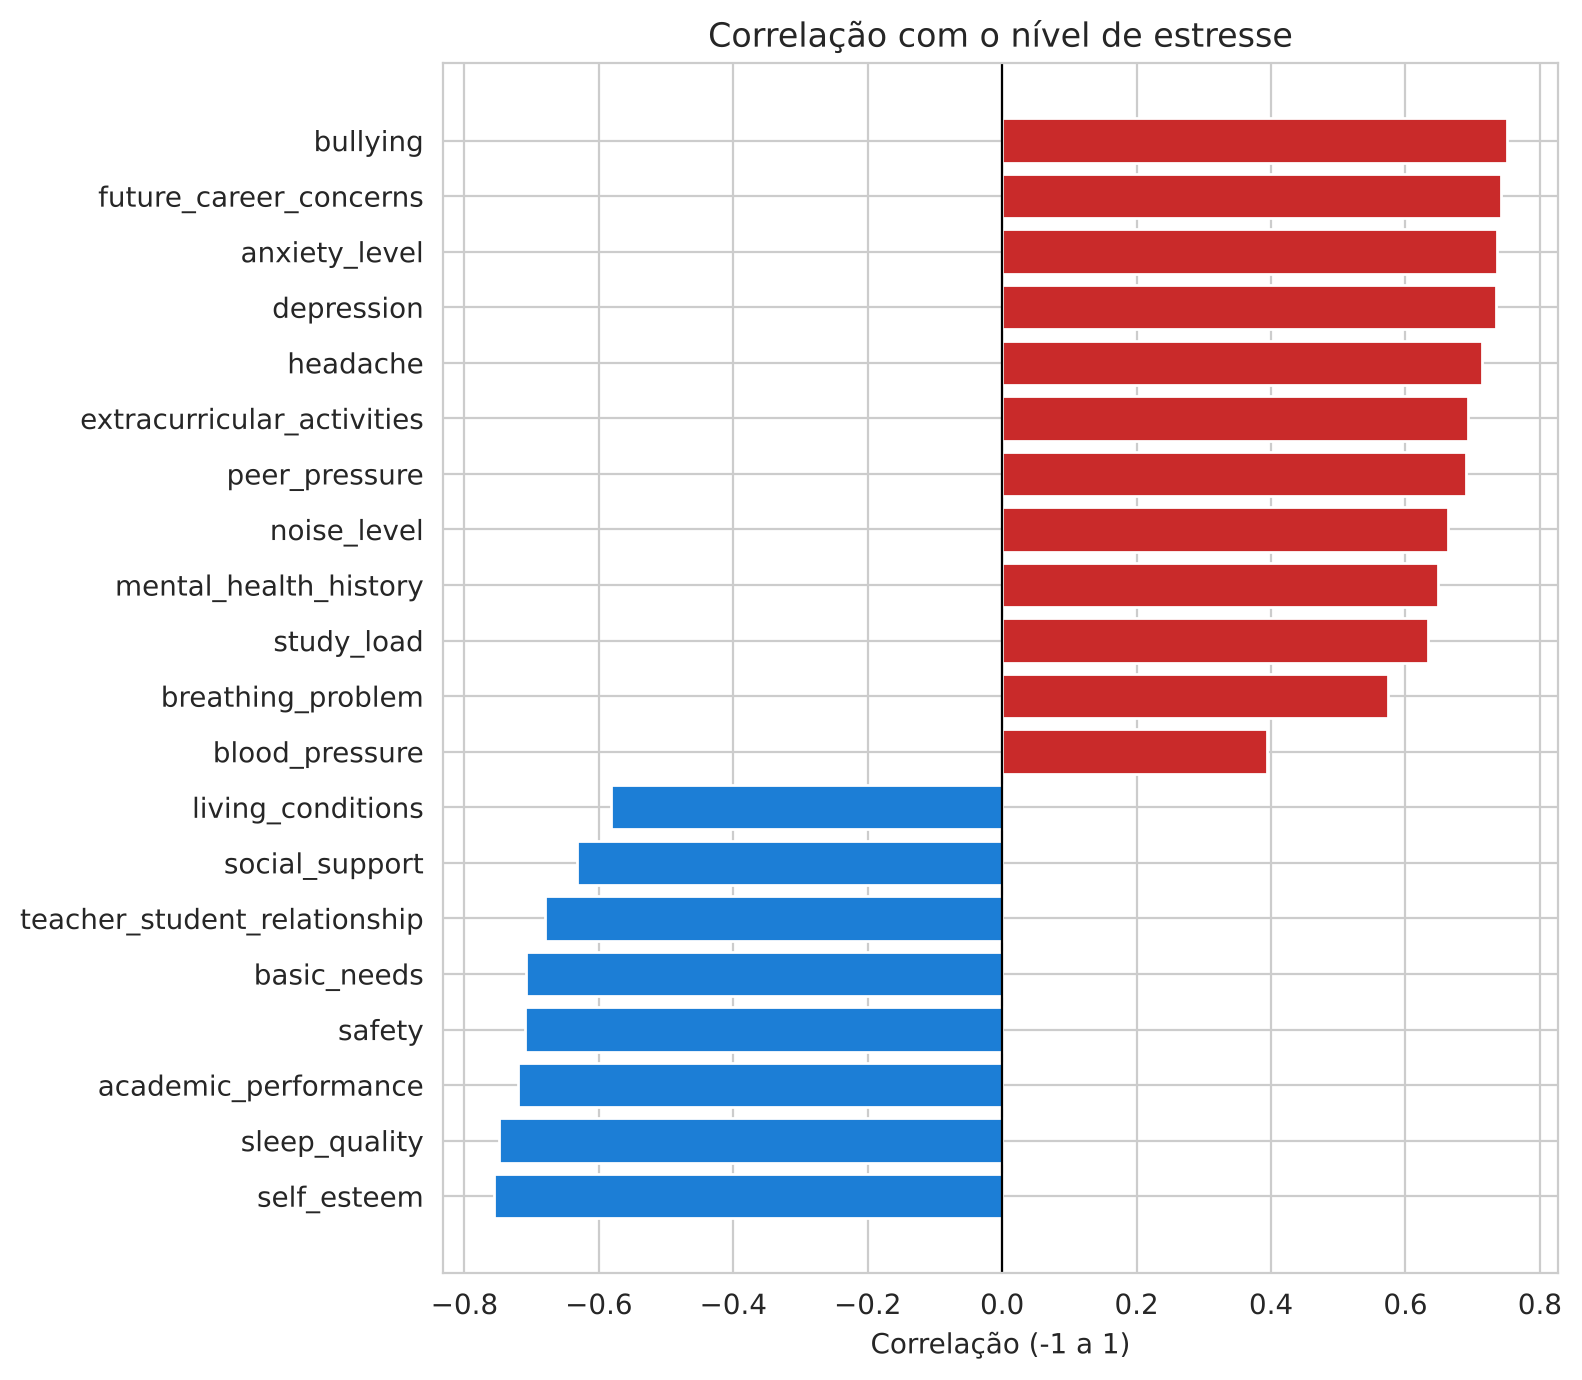

In [4]:
correlacao = df_estresse.corr()['stress_level'].drop('stress_level').sort_values()

with sns.axes_style('whitegrid'):
    plt.figure(figsize=(8, 7))
    cores = ['#C92A2A' if valor > 0 else '#1C7ED6' for valor in correlacao]
    plt.barh(correlacao.index, correlacao.values, color=cores)
    plt.axvline(0, color='black', linewidth=0.8)
    plt.title('Correlação com o nível de estresse')
    plt.xlabel('Correlação (-1 a 1)')
    plt.tight_layout()
    plt.show()

Em **vermelho** estão os fatores que aumentam junto com o estresse, e em **azul** os que diminuem quando o estresse aumenta.

- **Correlações positivas mais fortes:** bullying (0,75), preocupação com o futuro profissional (0,74), ansiedade (0,74), depressão (0,73) e dor de cabeça (0,71).
- **Correlações negativas mais fortes:** autoestima (−0,76), qualidade do sono (−0,75), desempenho acadêmico (−0,72), segurança (−0,71) e necessidades básicas atendidas (−0,71).
- A **pressão arterial** é o fator com a relação mais fraca (0,39).

Correlação mostra que dois fatores andam juntos, mas não prova que um causa o outro: dormir mal pode aumentar o estresse, e o estresse também pode piorar o sono.

## 2. Outliers

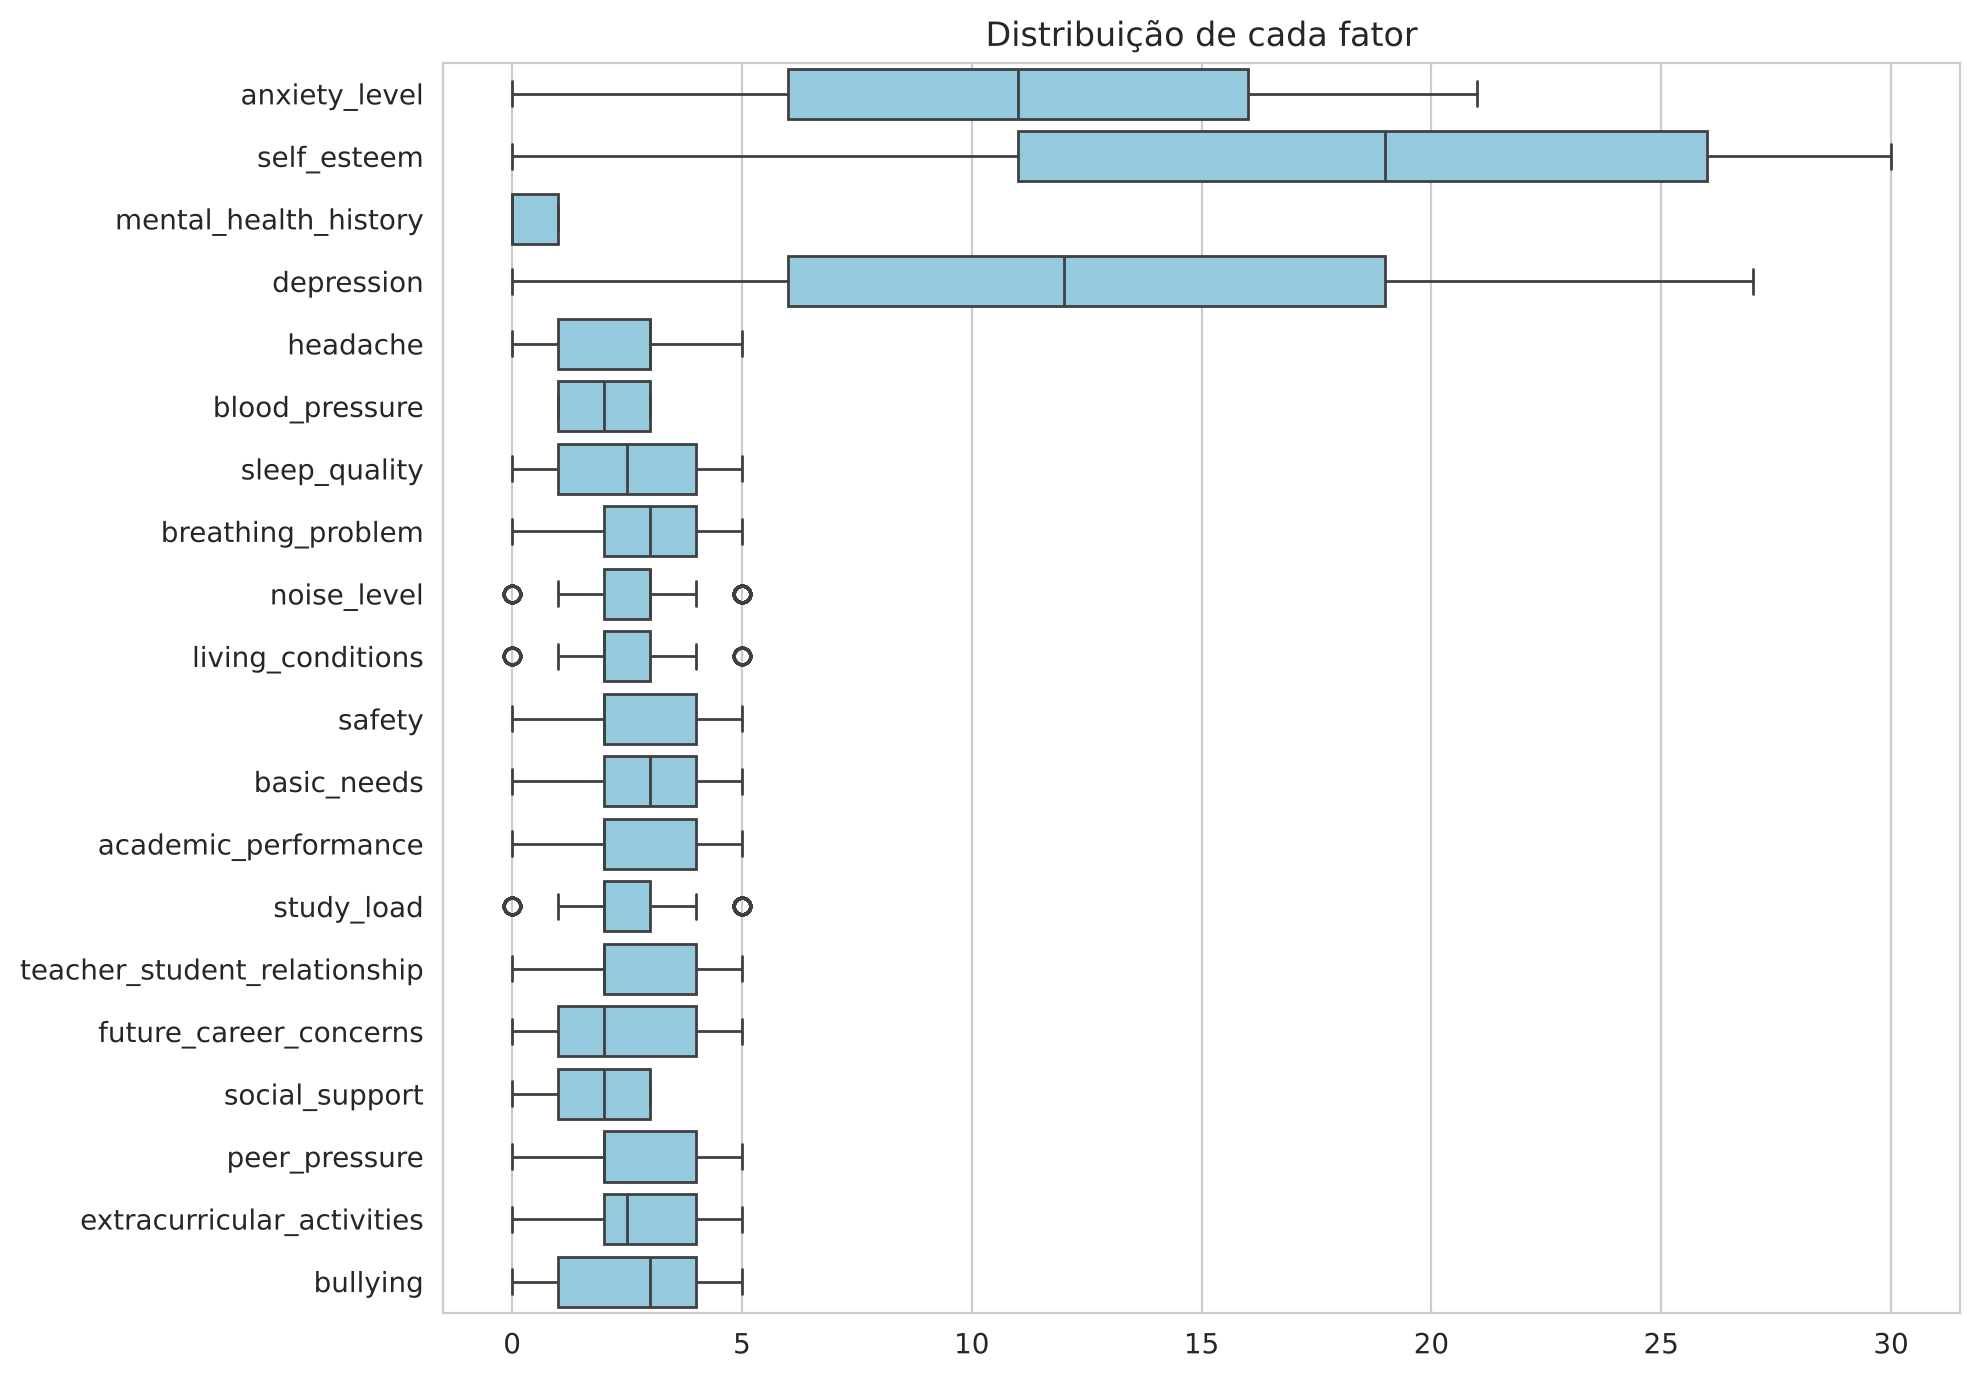

In [5]:
with sns.axes_style('whitegrid'):
    plt.figure(figsize=(10, 7))
    sns.boxplot(data=df_estresse.drop(columns=['stress_level']), orient='h', color='skyblue')
    plt.title('Distribuição de cada fator')
    plt.tight_layout()
    plt.show()

In [6]:
# outliers pela regra do boxplot: valores abaixo de Q1 - 1,5*IQR ou acima de Q3 + 1,5*IQR
q1 = df_estresse.quantile(0.25)
q3 = df_estresse.quantile(0.75)
iqr = q3 - q1
outliers = ((df_estresse < q1 - 1.5 * iqr) | (df_estresse > q3 + 1.5 * iqr)).sum()
outliers[outliers > 0]

noise_level          173
living_conditions     62
study_load           165
dtype: int64

A regra do boxplot aponta valores fora do padrão em `noise_level`, `living_conditions` e `study_load`. Mas todos estão dentro da escala de 0 a 5: são estudantes que responderam 0 ou 5 quando a maioria respondeu 2 ou 3. São respostas válidas, não erros de digitação, então ficam na base.

## 3. Variáveis do questionário

Para o questionário ficar curto, foram escolhidas **10 das 20 perguntas**: ansiedade, histórico de saúde mental, depressão, dor de cabeça, qualidade do sono, condições de vida, segurança, desempenho acadêmico, relação com os professores e bullying. Mais adiante, o modelo com essas 10 é comparado com o modelo que usa todas as 20, para ver quanto se perde ao encurtar o questionário.

In [7]:
perguntas = ['anxiety_level', 'mental_health_history', 'depression', 'headache', 'sleep_quality',
             'living_conditions', 'safety', 'academic_performance', 'teacher_student_relationship', 'bullying']
todas = df_estresse.drop(columns=['stress_level']).columns.tolist()
print(f'Questionário: {len(perguntas)} variáveis | Base completa: {len(todas)} variáveis')

Questionário: 10 variáveis | Base completa: 20 variáveis


## 4. Modelo

O nível de estresse tem **3 categorias** (0, 1 e 2), então este é um problema de **classificação**. Uma regressão linear devolveria números como 1,4 ou 2,3, que não são níveis de verdade, e o RMSE não diz quantos estudantes foram classificados certo. Por isso o modelo usado é a **regressão logística**, avaliada pela **acurácia** (a porcentagem de acertos).

A padronização fica dentro de um `pipeline`: a média e o desvio-padrão são calculados **só com os dados de treino**, sem vazar informação do teste.

In [8]:
y = df_estresse['stress_level']

def treinar_e_avaliar(colunas):
    x_treino, x_teste, y_treino, y_teste = train_test_split(
        df_estresse[colunas], y, test_size=0.25, random_state=123, stratify=y
    )
    modelo = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    modelo.fit(x_treino, y_treino)
    acuracia = accuracy_score(y_teste, modelo.predict(x_teste))
    return modelo, x_teste, y_teste, acuracia

modelo_todas, _, _, acuracia_todas = treinar_e_avaliar(todas)
modelo, x_teste, y_teste, acuracia = treinar_e_avaliar(perguntas)

print(f'Acurácia com as 20 variáveis: {acuracia_todas:.1%}')
print(f'Acurácia com as 10 do questionário: {acuracia:.1%}')

Acurácia com as 20 variáveis: 89.8%
Acurácia com as 10 do questionário: 86.5%


Com as 20 variáveis, o modelo acerta **89,8%** dos estudantes do teste. Com as 10 do questionário, acerta **86,5%**. Cortar metade das perguntas custa só cerca de 3 pontos de acurácia, o que justifica usar o questionário curto.

Para comparar: chutando um nível ao acaso, a acurácia seria de cerca de 33%.

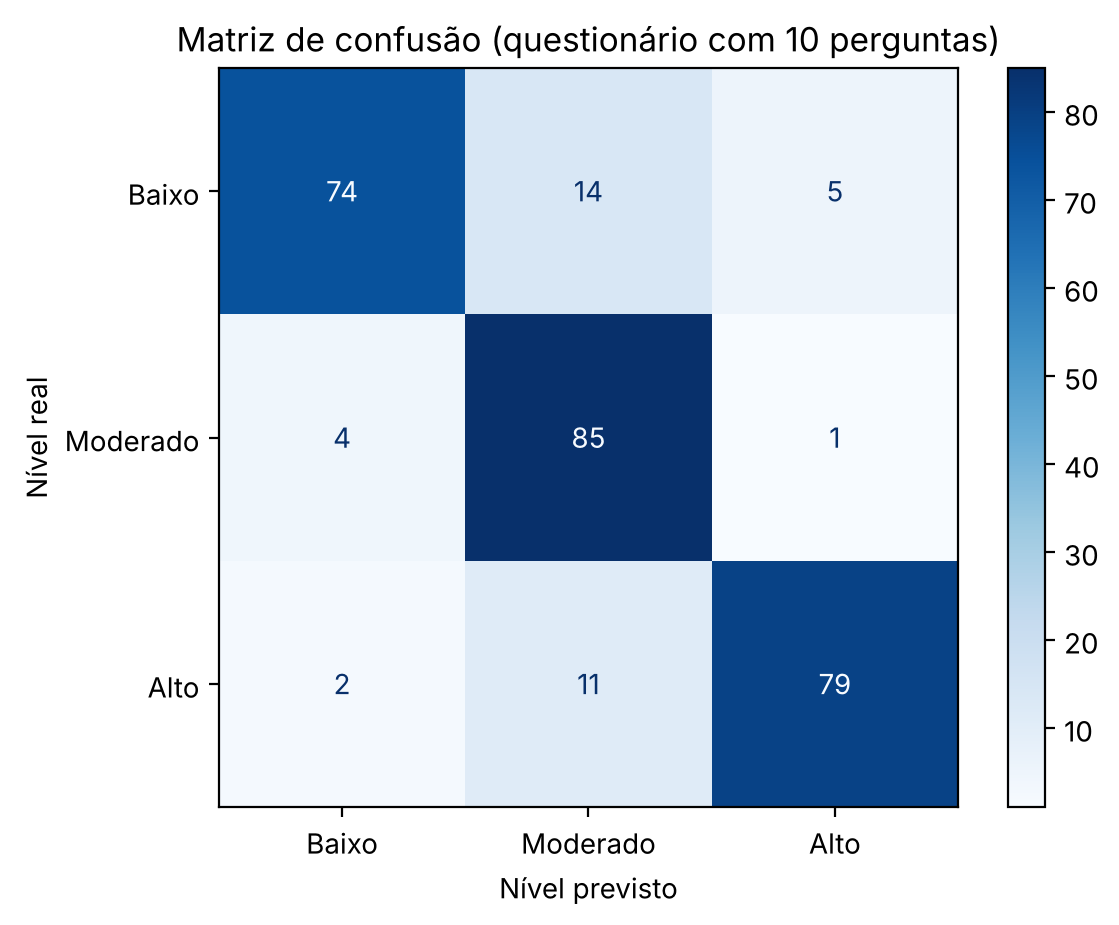

In [9]:
ConfusionMatrixDisplay.from_estimator(
    modelo, x_teste, y_teste,
    display_labels=['Baixo', 'Moderado', 'Alto'], cmap='Blues'
)
plt.title('Matriz de confusão (questionário com 10 perguntas)')
plt.xlabel('Nível previsto')
plt.ylabel('Nível real')
plt.show()

A diagonal mostra os acertos. A maior parte dos erros acontece entre **níveis vizinhos**: 14 estudantes com estresse baixo foram classificados como moderado, e 11 com estresse alto também como moderado. Confusões entre os extremos (baixo e alto) são raras: 5 e 2 casos.

In [10]:
coeficientes = pd.DataFrame(
    modelo[-1].coef_.T, index=perguntas, columns=['Baixo', 'Moderado', 'Alto']
).round(2)
coeficientes.sort_values('Alto')

,Baixo,Moderado,Alto
academic_performance,0.66,-0.04,-0.61
sleep_quality,0.59,-0.03,-0.57
safety,0.53,-0.10,-0.43
living_conditions,0.12,-0.05,-0.07
teacher_student_relationship,0.05,-0.00,-0.04
anxiety_level,-0.30,0.23,0.07
mental_health_history,-0.09,-0.05,0.14
depression,-0.36,-0.32,0.69
headache,-0.62,-0.08,0.70
bullying,-0.58,-0.16,0.74


Cada coluna mostra o quanto cada fator "puxa" a previsão para aquele nível: valores positivos aumentam a chance, e negativos diminuem.

- Para o estresse **alto**, os fatores que mais pesam são **bullying**, **dor de cabeça** e **depressão**.
- **Desempenho acadêmico**, **qualidade do sono** e **segurança** puxam a previsão para o estresse **baixo**.
- **Relação com os professores** e **condições de vida** quase não mudam a previsão quando o modelo já conhece os outros fatores.

## 5. Questionário

A função recebe as respostas na escala original de cada pergunta e devolve o nível de estresse previsto, com a probabilidade de cada nível. As respostas fora da escala são ajustadas para o limite mais próximo.

In [11]:
escalas = {
    'anxiety_level': (0, 21), 'mental_health_history': (0, 1), 'depression': (0, 27),
    'headache': (0, 5), 'sleep_quality': (0, 5), 'living_conditions': (0, 5), 'safety': (0, 5),
    'academic_performance': (0, 5), 'teacher_student_relationship': (0, 5), 'bullying': (0, 5),
}
niveis = ['baixo', 'moderado', 'alto']

def prever_estresse(respostas):
    ajustadas = {coluna: min(max(respostas[coluna], minimo), maximo)
                 for coluna, (minimo, maximo) in escalas.items()}
    estudante = pd.DataFrame([ajustadas])[perguntas]
    nivel = modelo.predict(estudante)[0]
    probabilidades = modelo.predict_proba(estudante)[0]
    print(f'Nível de estresse previsto: {niveis[nivel]}')
    for nome, prob in zip(niveis, probabilidades):
        print(f'  {nome}: {prob:.0%}')
    return nivel

Exemplo: um estudante com ansiedade e depressão altas, que dorme mal e sofre bullying.

In [12]:
estudante = {
    'anxiety_level': 18, 'mental_health_history': 1, 'depression': 20, 'headache': 4,
    'sleep_quality': 1, 'living_conditions': 2, 'safety': 2, 'academic_performance': 2,
    'teacher_student_relationship': 1, 'bullying': 4,
}
prever_estresse(estudante);

Nível de estresse previsto: alto
  baixo: 0%
  moderado: 13%
  alto: 87%


Para responder você mesmo, rode `questionario()` na célula abaixo. As perguntas usam a mesma escala dos dados.

In [13]:
def perguntar(texto, minimo, maximo):
    while True:
        try:
            valor = int(input(f'{texto} ({minimo} a {maximo}): '))
            if minimo <= valor <= maximo:
                return valor
            print(f'Digite um número entre {minimo} e {maximo}.')
        except ValueError:
            print('Digite apenas números inteiros.')

def questionario():
    textos = {
        'anxiety_level': 'Qual o seu nível de ansiedade?',
        'mental_health_history': 'Você tem histórico de problemas de saúde mental? (1 = sim, 0 = não)',
        'depression': 'Qual o seu nível de depressão?',
        'headache': 'Com que frequência você tem dor de cabeça?',
        'sleep_quality': 'Qual a qualidade do seu sono?',
        'living_conditions': 'Como são as suas condições de vida?',
        'safety': 'O quanto você se sente seguro(a)?',
        'academic_performance': 'Como está o seu desempenho acadêmico?',
        'teacher_student_relationship': 'Como é a sua relação com os professores?',
        'bullying': 'O quanto você sofre ou sofreu bullying?',
    }
    respostas = {coluna: perguntar(textos[coluna], *escalas[coluna]) for coluna in perguntas}
    return prever_estresse(respostas)

# questionario()

## Conclusão

- Bullying, ansiedade, depressão, dor de cabeça e preocupação com o futuro são os fatores mais ligados a um estresse alto. Autoestima, sono, desempenho acadêmico e segurança andam no sentido contrário.
- Como o nível de estresse é uma categoria (baixo, moderado ou alto), o problema é de **classificação**. A regressão logística acerta **86,5%** dos casos usando só 10 perguntas, contra 89,8% com todas as 20.
- Quando o modelo erra, quase sempre confunde níveis vizinhos, e raramente troca estresse baixo por alto.
- O questionário mostra como o modelo poderia ser usado na prática, mas é um exercício de estudo e não substitui uma avaliação profissional.